In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 2 DSP Laboratory Started Successfully")

Week 2 DSP Laboratory Started Successfully



## Pre-Lab Questions

### Question 1(a)

A 7 kHz tone is sampled at 10 kHz. Find the frequency that appears.

Given:
F = 7 kHz
fs = 10 kHz

Nyquist frequency = fs/2 = 5 kHz.

Since 7 kHz is above the Nyquist frequency, aliasing occurs.

Falias = |7 - 10|

Falias = 3 kHz.

Answer: The frequency that appears is 3 kHz.

### Question 1(b)

Calculate the quantization step and theoretical SQNR for an 8-bit quantizer with a ±1 V range.

Given:
B = 8 bits
Xm = 1 V

Delta = 2Xm / 2^B

Delta = 2/256

Delta = 0.0078125 V

Theoretical SQNR = 6.02B + 1.76

= 6.02(8) + 1.76

= 49.92 dB.

Answer:
Quantization step = 0.0078125 V.
Theoretical SQNR = 49.92 dB.


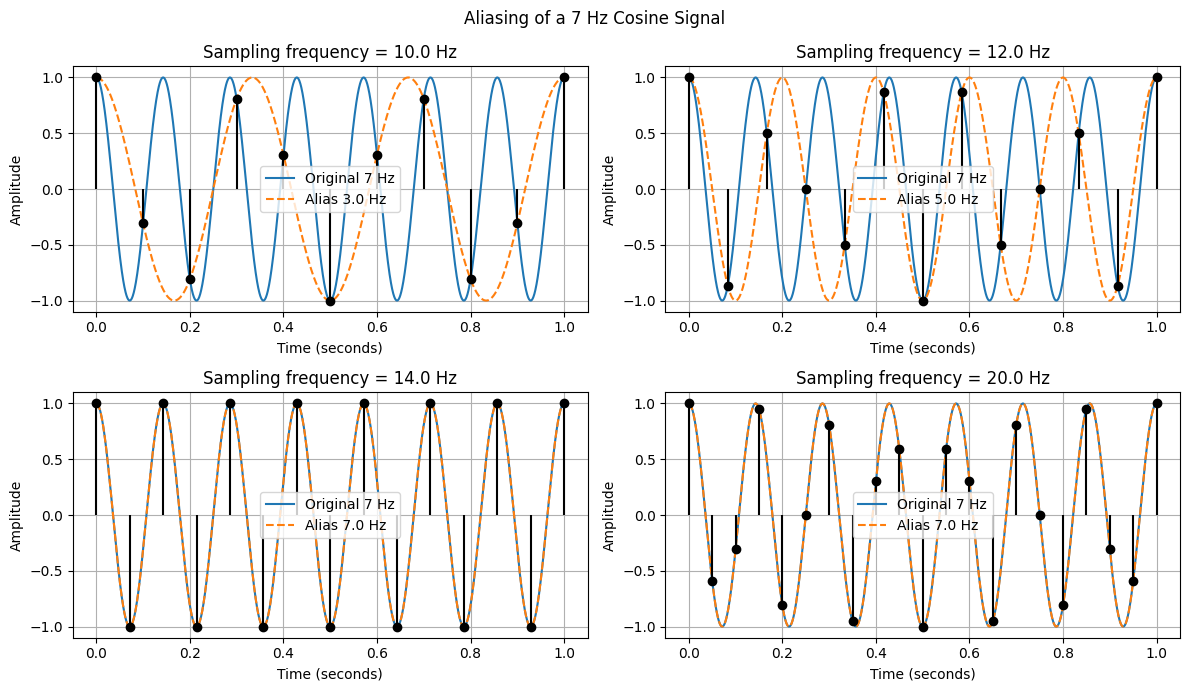

ALIAS FREQUENCY TABLE
---------------------
Sampling Rate (Hz) | Alias Frequency (Hz)
             10.0 |                 3.0
             12.0 |                 5.0
             14.0 |                 7.0
             20.0 |                 7.0


In [2]:

# TASK 2.1: ALIASING OF A SINUSOID

# Original signal frequency
f0 = 7.0

# Sampling frequencies to test
sampling_rates = [10.0, 12.0, 14.0, 20.0]

# Dense time grid representing the original signal
t = np.linspace(0, 1, 2000)

# Create four graphs
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# Store alias frequencies
alias_table = []

for ax, fs in zip(axes.flat, sampling_rates):

    # Sample indices
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    # Calculate alias frequency
    k = round(f0 / fs)
    f_alias = abs(f0 - fs * k)

    # Original continuous signal
    x = np.cos(2 * np.pi * f0 * t)

    # Alias signal
    x_alias = np.cos(2 * np.pi * f_alias * t)

    # Sampled signal
    x_sampled = np.cos(2 * np.pi * f0 * tn)

    # Plot signals
    ax.plot(t, x, label="Original 7 Hz")
    ax.plot(t, x_alias, "--", label=f"Alias {f_alias} Hz")

    ax.stem(
        tn, x_sampled,
        linefmt="k-",
        markerfmt="ko",
        basefmt=" "
    )

    ax.set_title(f"Sampling frequency = {fs} Hz")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

    alias_table.append((fs, f_alias))

plt.suptitle("Aliasing of a 7 Hz Cosine Signal")
plt.tight_layout()
plt.show()

# Display alias frequency table
print("ALIAS FREQUENCY TABLE")
print("---------------------")
print("Sampling Rate (Hz) | Alias Frequency (Hz)")

for fs, fa in alias_table:
    print(f"{fs:17.1f} | {fa:19.1f}")



### Observation

The original cosine signal has a frequency of 7 Hz.

When the sampling frequency is 10 Hz, aliasing occurs
and the signal appears at 3 Hz.

At 12 Hz, the alias frequency is 5 Hz.

At 14 Hz, the signal is sampled exactly at the Nyquist
rate, which is 7 Hz.

At 20 Hz, the sampling frequency is above the Nyquist
rate, and the original 7 Hz signal can be represented
without aliasing.

Therefore, the sampling frequency must be at least
twice the highest frequency component to satisfy the
Nyquist sampling condition.



## Task 2.1 – Aliasing of a Sinusoid

The objective of this task is to demonstrate aliasing
by sampling a 7 Hz cosine signal at different sampling
frequencies and observing the resulting alias frequencies.



## Task 2.2 – Hear Aliasing

**Objective:**

To demonstrate aliasing in a real audio signal by
downsampling a voice recording with and without
an anti-aliasing filter.

The recording used is Swaum's voice recording.


In [7]:

import subprocess
import glob

# Find Swaum's audio file
files = glob.glob("/content/*Swaum*")

if not files:
    print("Swaum audio file not found.")
else:
    input_file = files[0]

    output_file = "/content/Swaum_voice.wav"

    result = subprocess.run([
        "ffmpeg", "-y",
        "-i", input_file,
        "-vn",
        "-ac", "1",
        "-ar", "48000",
        output_file
    ], capture_output=True, text=True)

    if result.returncode == 0:
        print("SUCCESS! Swaum audio extracted.")
        print("Saved as:", output_file)
    else:
        print(result.stderr[-2000:])


SUCCESS! Swaum audio extracted.
Saved as: /content/Swaum_voice.wav


In [8]:

import os
import glob
import subprocess

# Find Swaum's audio file
files = glob.glob("/content/*Swaum*")

print("Available Swaum recordings:")
for f in files:
    print(os.path.basename(f))

# Use existing WAV if available
wav_files = glob.glob("/content/*Swaum*.wav")

if wav_files:
    audio_path = wav_files[0]
    print("\nWAV file is ready:", audio_path)

else:
    # Convert uploaded recording to WAV
    audio_files = [
        f for f in files
        if f.lower().endswith((".m4a", ".mp4"))
    ]

    if not audio_files:
        raise FileNotFoundError("Please upload Swaum's recording.")

    audio_path = "/content/Swaum_voice.wav"

    result = subprocess.run([
        "ffmpeg", "-y",
        "-i", audio_files[0],
        "-vn", "-ac", "1",
        audio_path
    ], capture_output=True, text=True)

    if result.returncode != 0:
        print(result.stderr[-2000:])
        raise RuntimeError("Audio conversion failed.")

    print("\nAudio conversion successful!")
    print(audio_path)


Available Swaum recordings:
Swaum voice.m4a.mp4
Swaum_voice.wav

WAV file is ready: /content/Swaum_voice.wav


In [9]:

# TASK 2.2: HEAR ALIASING

import numpy as np
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

# Load Swaum's voice recording
fs, x = wavfile.read(audio_path)

# Convert stereo to mono
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize audio
x = x.astype(float)

if np.max(np.abs(x)) > 0:
    x = x / np.max(np.abs(x))

print("Original sampling rate:", fs, "Hz")
print("Recording duration:", len(x)/fs, "seconds")

# Test downsampling factors
for k in [2, 4, 8]:

    # Naive downsampling
    naive = x[::k]

    # Proper downsampling with anti-aliasing filter
    proper = signal.decimate(x, k, ftype="fir")

    # New sampling frequency
    new_fs = fs // k

    print("\n================================")
    print("Downsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")

    print("NAIVE DOWNSAMPLING:")
    display(Audio(naive, rate=new_fs))

    print("PROPER DOWNSAMPLING:")
    display(Audio(proper, rate=new_fs))


Original sampling rate: 48000 Hz
Recording duration: 4.8213333333333335 seconds

Downsampling factor: 2
New sampling rate: 24000 Hz
NAIVE DOWNSAMPLING:


PROPER DOWNSAMPLING:



Downsampling factor: 4
New sampling rate: 12000 Hz
NAIVE DOWNSAMPLING:


PROPER DOWNSAMPLING:



Downsampling factor: 8
New sampling rate: 6000 Hz
NAIVE DOWNSAMPLING:


PROPER DOWNSAMPLING:



### Observation

The original voice recording was downsampled using
three different factors: 2, 4 and 8.

In naive downsampling, samples were removed without
applying an anti-aliasing filter. This can introduce
aliasing and distortion into the audio signal.

In proper downsampling, an anti-aliasing low-pass
filter was applied before reducing the sampling rate.
This helps to remove high-frequency components that
could cause aliasing.

For a downsampling factor of 8, the sampling rate
was reduced significantly, making the difference
between the filtered and unfiltered recordings more
noticeable.

The filtered recording generally preserves the
original voice more accurately than naive downsampling.

### Conclusion

An anti-aliasing filter is important in digital signal
processing because it reduces unwanted frequency
components before downsampling and helps preserve
the quality of the original audio signal.



## Task 2.3 – A Uniform Quantizer

**Objective:**

To implement a uniform quantizer and observe
the difference between the original signal,
quantized signal and quantization error.


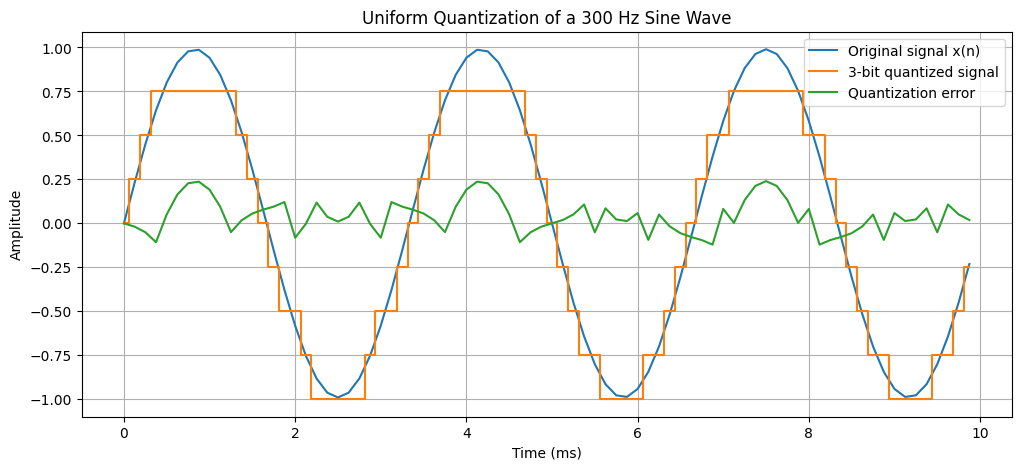

UNIFORM QUANTIZER RESULTS
-------------------------
Sampling frequency: 8000 Hz
Signal frequency: 300 Hz
Quantization bits: 3
Number of levels: 8
Quantization step: 0.25


In [10]:

# TASK 2.3: A UNIFORM QUANTIZER

# Define uniform quantizer
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Sampling frequency
fs = 8000

# Generate time values
t = np.arange(0, 0.01, 1/fs)

# Generate 300 Hz sine wave
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Apply 3-bit quantization
xq = quantize(x, 3)

# Calculate quantization error
error = x - xq

# Plot the signals
plt.figure(figsize=(12, 5))

plt.plot(t * 1e3, x, label="Original signal x(n)")
plt.step(t * 1e3, xq, where="mid", label="3-bit quantized signal")
plt.plot(t * 1e3, error, label="Quantization error")

plt.title("Uniform Quantization of a 300 Hz Sine Wave")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

# Display quantization information
delta = 2 / 2**3

print("UNIFORM QUANTIZER RESULTS")
print("-------------------------")
print("Sampling frequency:", fs, "Hz")
print("Signal frequency: 300 Hz")
print("Quantization bits: 3")
print("Number of levels:", 2**3)
print("Quantization step:", delta)



### Observation

The original signal is a 300 Hz sine wave with an
amplitude of 0.99.

After applying a 3-bit uniform quantizer, the signal
is represented using 8 quantization levels.

The quantized signal has a staircase appearance
because its amplitude is restricted to discrete levels.

The difference between the original signal and the
quantized signal is called quantization error.

Increasing the number of bits increases the number
of quantization levels and generally reduces the
quantization error.



## Task 2.4 – Verify the 6 dB-per-bit rule

**Objective:**

To calculate measured and theoretical Signal-to-
Quantization-Noise Ratio (SQNR) for different
quantization bit depths and verify the 6 dB-per-bit rule.


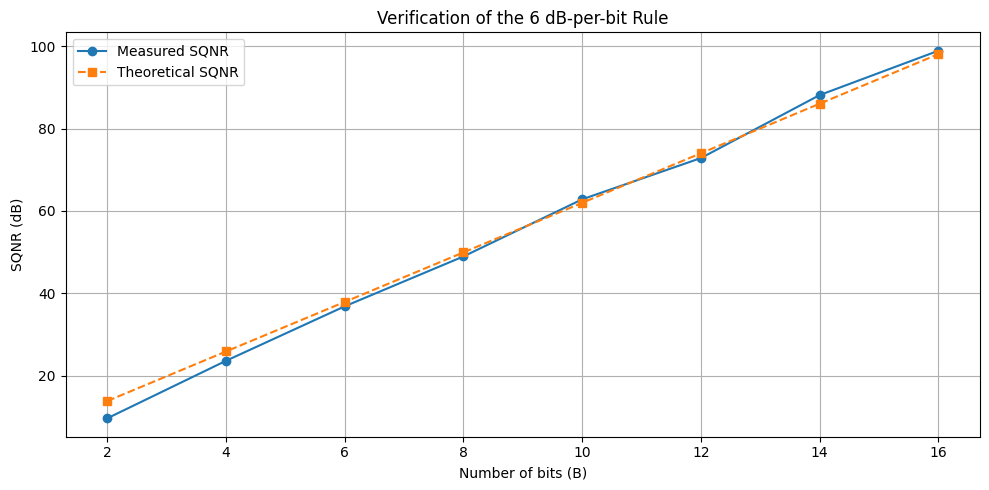

SQNR RESULTS
-----------------------------------
Bits | Measured SQNR | Theoretical SQNR
   2 |           9.60 |             13.80
   4 |          23.58 |             25.84
   6 |          36.81 |             37.88
   8 |          48.93 |             49.92
  10 |          62.81 |             61.96
  12 |          72.84 |             74.00
  14 |          88.13 |             86.04
  16 |          98.91 |             98.08


In [11]:

# TASK 2.4: VERIFY THE 6 dB-PER-BIT RULE

import numpy as np
import matplotlib.pyplot as plt

# Define uniform quantizer
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Generate original sine wave
fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Quantization bits
bits = np.arange(2, 17, 2)

# Calculate measured SQNR
measured = []

for B in bits:
    xq = quantize(x, B)
    error = x - xq

    sqnr = 10 * np.log10(
        np.sum(x**2) / np.sum(error**2)
    )

    measured.append(sqnr)

# Calculate theoretical SQNR
theoretical = 6.02 * bits + 1.76

# Plot measured and theoretical SQNR
plt.figure(figsize=(10, 5))

plt.plot(bits, measured, "o-", label="Measured SQNR")
plt.plot(bits, theoretical, "s--", label="Theoretical SQNR")

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")

plt.xticks(bits)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Print results
print("SQNR RESULTS")
print("-----------------------------------")
print("Bits | Measured SQNR | Theoretical SQNR")

for B, m, th in zip(bits, measured, theoretical):
    print(f"{B:4d} | {m:14.2f} | {th:17.2f}")



### Observation

The measured and theoretical SQNR values were
calculated for quantization levels ranging from
2 bits to 16 bits.

The graph shows that SQNR increases as the number
of quantization bits increases.

The theoretical SQNR increases by approximately
6 dB whenever one additional bit is used.

The measured SQNR generally follows the theoretical
values, although small differences may occur because
of the signal amplitude, sampling and quantization error.

### Conclusion

The experiment verifies the 6 dB-per-bit rule.
Increasing the number of quantization bits improves
signal quality by reducing quantization noise.



## Task 2.5 – Quantize Your Voice

**Objective:**

To quantize a real voice recording using 4-bit,
8-bit and 12-bit quantizers, listen to the
different versions and calculate their SQNR.


In [12]:

# TASK 2.5: QUANTIZE YOUR VOICE

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

# Load Swaum's voice recording
fs, audio = wavfile.read("/content/Swaum_voice.wav")

# Convert stereo to mono
if audio.ndim > 1:
    audio = audio.mean(axis=1)

# Normalize audio
audio = audio.astype(float)
audio = audio / np.max(np.abs(audio))

# Define uniform quantizer
def quantize_voice(x, bits):
    delta = 2 / (2**bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -1, 1 - delta)

# Test 4, 8 and 12 bits
bit_values = [4, 8, 12]
results = []

for B in bit_values:

    # Quantize voice
    xq = quantize_voice(audio, B)

    # Calculate quantization error
    error = audio - xq

    # Calculate SQNR
    sqnr = 10 * np.log10(
        np.sum(audio**2) / np.sum(error**2)
    )

    results.append((B, sqnr))

    print("\n--------------------------")
    print("Quantization:", B, "bits")
    print("Number of levels:", 2**B)
    print("Measured SQNR:", round(sqnr, 2), "dB")

    # Play quantized voice
    print("Listen to", B, "bit recording:")
    display(Audio(xq, rate=fs))

# Display SQNR results
print("\nFINAL SQNR RESULTS")
print("--------------------------")
print("Bits | Measured SQNR (dB)")

for B, sqnr in results:
    print(f"{B:4d} | {sqnr:18.2f}")



--------------------------
Quantization: 4 bits
Number of levels: 16
Measured SQNR: 10.51 dB
Listen to 4 bit recording:



--------------------------
Quantization: 8 bits
Number of levels: 256
Measured SQNR: 34.06 dB
Listen to 8 bit recording:



--------------------------
Quantization: 12 bits
Number of levels: 4096
Measured SQNR: 58.15 dB
Listen to 12 bit recording:



FINAL SQNR RESULTS
--------------------------
Bits | Measured SQNR (dB)
   4 |              10.51
   8 |              34.06
  12 |              58.15



### Observation

The original voice recording was quantized using
4-bit, 8-bit and 12-bit quantizers.

The 4-bit quantizer provides 16 levels and produces
more quantization noise.

The 8-bit quantizer provides 256 levels and produces
better audio quality than the 4-bit quantizer.

The 12-bit quantizer provides 4096 levels and
preserves the original voice more accurately.

The SQNR generally increases as the number of
quantization bits increases.

### Analysis Question

Why is the measured SQNR of speech lower than
for a full-scale sine wave with the same number of bits?

Speech signals have varying amplitudes and do not
use the full quantization range continuously.
Some speech portions have low amplitudes, making
quantization noise more significant compared to
the actual signal power.

Therefore, speech generally has a lower measured
SQNR than a full-scale sine wave using the same
number of bits.

### Conclusion

Increasing the number of quantization bits reduces
quantization noise and improves the quality of
the recorded voice signal.


# COU07506 – DIGITAL SIGNAL PROCESSING

## WEEK 2 – LAB 1A
### SAMPLING, ALIASING AND QUANTIZATION

**Name:** Swaum Hussen Idd

**Registration Number:** 240242406676

**Institution:** Dar es Salaam Institute of Technology

**Department:** Computer Studies Department

**Academic Year:** 2026/2027